<a href="https://colab.research.google.com/github/Rahardirizky/modul-soil-improvement/blob/main/modul_M4_Asaoka.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M4 — Prediksi Penurunan Akhir dengan Metode Asaoka

**Tujuan:** memperkirakan penurunan akhir (*ultimate settlement*) dari data monitoring settlement plate menggunakan metode observasional Asaoka (1978).

Alur notebook: **teori → fungsi → contoh penggunaan → visualisasi → unit test → validasi paper**.

> Contoh numerik bersifat ilustratif, bukan data proyek C-2. Data C-2 digunakan sebagai konteks studi kasus; angka yang dibaca dari grafik tidak dianggap sebagai data mentah presisi.

**Pembaruan:** M4 juga memuat verifikasi hasil yang dilaporkan, pemeriksaan surcharge, dan pemeriksaan laju penurunan sisa.

## 1. Dasar teori

Untuk pembacaan settlement pada interval waktu konstan \(\Delta t\), metode Asaoka menyatakan:

\[
S_n = \beta_0 + \beta_1 S_{n-1}
\]

\(S_n\) adalah settlement pada waktu pengamatan ke-\(n\), \(S_{n-1}\) adalah settlement pada waktu sebelumnya, \(\beta_0\) adalah intercept, dan \(\beta_1\) adalah slope regresi.

Pada kondisi akhir, \(S_n=S_{n-1}=S_f\), sehingga:

\[
\boxed{S_f=\frac{\beta_0}{1-\beta_1}}
\]

Derajat konsolidasi berbasis settlement dapat dihitung:

\[
U(t)=\frac{S(t)-S_0}{S_f-S_0}\times100\%
\]

\(S_0\) adalah settlement pada awal periode evaluasi. Jika datum pengukuran dimulai dari nol, \(S_0=0\).

**Syarat dan batasan:** interval waktu harus tetap; rentang data harus mewakili tahap konsolidasi yang cukup berkembang; perubahan tahapan beban dan secondary settlement dapat memengaruhi regresi; \(S_f\) merupakan ekstrapolasi observasional, bukan pengukuran langsung.

## 2. Referensi dan traceability

| Topik | Referensi | Lokasi |
|---|---|---|
| Interval tetap, plot \(S_n\) terhadap \(S_{n-1}\), titik potong | Materi kuliah MPT Minggu 3 | Bagian 3.6, halaman slide 53 |
| Pengaruh \(\Delta t\), secondary settlement, data awal | Presentasi C-2, *Pengalaman Perbaikan Tanah* | Slide 111 |
| Metode observasional Asaoka | Asaoka (1978) | *Soils and Foundations*, 18(4), pp. 87–101 |

**Sumber primer:** Asaoka, A. (1978). *Observational Procedure of Settlement Prediction*. Soils and Foundations, 18(4), 87–101. DOI: https://doi.org/10.3208/sandf1972.18.4_87

Sumber pendukung: Arafianto et al., *Jurnal Teknik Sipil ITB*, bagian 3.2.1, “Interpretasi data hasil pengukuran — Metode Asaoka”: https://journals.itb.ac.id/index.php/jts/article/view/16878/5908

Persamaan \(S_f=\beta_0/(1-\beta_1)\) diperoleh dari kondisi titik potong \(S_n=S_{n-1}\).

## 3. Import library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 4. Fungsi persiapan data

Memeriksa panjang data, nilai numerik, urutan waktu, dan interval waktu tetap. Rentang analisis dapat dipilih dengan `start_time` dan `end_time`.

In [ ]:
def prepare_asaoka_data(time, settlement, start_time=None, end_time=None, interval_tolerance=1e-6):
    """Prepare equally spaced time-settlement observations.

    time: observation time (e.g. days)
    settlement: measured settlement (e.g. mm)
    start_time, end_time: optional inclusive analysis-window limits
    interval_tolerance: absolute tolerance in the time unit
    Returns selected data, constant interval, and consecutive settlement pairs.
    """
    t = np.asarray(time, dtype=float)
    s = np.asarray(settlement, dtype=float)

    if t.ndim != 1 or s.ndim != 1 or len(t) != len(s):
        raise ValueError("time and settlement must be 1D arrays with equal length.")
    if len(t) < 3:
        raise ValueError("At least 3 observations are required.")
    if not np.all(np.isfinite(t)) or not np.all(np.isfinite(s)):
        raise ValueError("time and settlement must contain finite values.")
    if np.any(np.diff(t) <= 0):
        raise ValueError("time must be strictly increasing.")

    mask = np.ones(len(t), dtype=bool)
    if start_time is not None:
        mask &= t >= start_time
    if end_time is not None:
        mask &= t <= end_time
    t_sel, s_sel = t[mask], s[mask]

    if len(t_sel) < 3:
        raise ValueError("Selected window must contain at least 3 observations.")

    intervals = np.diff(t_sel)
    delta_t = float(np.mean(intervals))
    if not np.allclose(intervals, delta_t, rtol=0.0, atol=interval_tolerance):
        raise ValueError("Selected observations must have a constant time interval.")

    return {
        "time": t_sel,
        "settlement": s_sel,
        "delta_t": delta_t,
        "settlement_previous": s_sel[:-1],
        "settlement_current": s_sel[1:],
        "pair_time": t_sel[1:]
    }

## 5. Fungsi analisis Asaoka

Regresi linear menggunakan \(S_{n-1}\) sebagai X dan \(S_n\) sebagai Y. Keluaran meliputi \(\beta_0\), \(\beta_1\), \(R^2\), dan settlement akhir \(S_f\).

In [ ]:
def calculate_asaoka_final_settlement(beta0, beta1):
    """Calculate ultimate settlement from reported Asaoka coefficients."""
    beta0, beta1 = float(beta0), float(beta1)
    if not np.isfinite(beta0) or not np.isfinite(beta1):
        raise ValueError("Asaoka coefficients must be finite.")
    if beta0 < 0 or not 0 <= beta1 < 1:
        raise ValueError("Require beta0 >= 0 and 0 <= beta1 < 1.")
    return beta0 / (1.0 - beta1)


In [ ]:
def calculate_asaoka(settlement_previous, settlement_current):
    """Fit Sn = beta0 + beta1*Sn-1 and estimate final settlement.

    Inputs: consecutive settlement pairs in the same length unit.
    Outputs: beta0, beta1, R-squared, and final settlement in that unit.
    """
    x = np.asarray(settlement_previous, dtype=float)
    y = np.asarray(settlement_current, dtype=float)

    if x.ndim != 1 or y.ndim != 1 or len(x) != len(y):
        raise ValueError("Settlement pair arrays must be 1D and have equal length.")
    if len(x) < 2:
        raise ValueError("At least 2 settlement pairs are required.")
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError("Settlement pairs must contain finite values.")
    if np.allclose(x, x[0]):
        raise ValueError("Previous settlement values must not all be identical.")

    beta1, beta0 = np.polyfit(x, y, 1)
    y_fit = beta0 + beta1*x
    ss_res = float(np.sum((y-y_fit)**2))
    ss_tot = float(np.sum((y-np.mean(y))**2))
    r_squared = 1.0 - ss_res/ss_tot if ss_tot > 0 else np.nan

    if beta1 >= 1.0:
        raise ValueError("beta1 must be less than 1 for finite final settlement.")
    final_settlement = calculate_asaoka_final_settlement(beta0, beta1)

    return {"beta0": float(beta0), "beta1": float(beta1),
            "r_squared": float(r_squared), "final_settlement": float(final_settlement)}

## 6. Fungsi derajat konsolidasi

Derajat konsolidasi dihitung relatif terhadap settlement awal pada periode evaluasi. Settlement terukur dan settlement akhir harus menggunakan datum serta satuan yang sama.

In [ ]:
def calculate_degree_of_consolidation(settlement, final_settlement, initial_settlement=0.0):
    """Calculate settlement-based degree of consolidation (%).

    settlement, final_settlement, initial_settlement use the same length unit.
    """
    s = np.asarray(settlement, dtype=float)
    sf, s0 = float(final_settlement), float(initial_settlement)
    if not np.all(np.isfinite(s)) or not np.isfinite(sf) or not np.isfinite(s0):
        raise ValueError("Settlement values must be finite.")
    if sf <= s0:
        raise ValueError("final_settlement must exceed initial_settlement.")
    return (s-s0)/(sf-s0)*100.0

## 7. Fungsi terintegrasi

In [ ]:
def analyze_asaoka(time, settlement, start_time=None, end_time=None,
                   initial_settlement=None, interval_tolerance=1e-6):
    """Run data preparation, Asaoka regression, and settlement-based U calculation.

    time: monitoring time (e.g. days)
    settlement: measured settlement (e.g. mm)
    start_time/end_time: optional analysis-window limits
    initial_settlement: datum at start of evaluated period; defaults to first selected reading
    """
    prepared = prepare_asaoka_data(
        time, settlement, start_time, end_time, interval_tolerance
    )
    fitted = calculate_asaoka(
        prepared["settlement_previous"], prepared["settlement_current"]
    )
    s0 = (float(prepared["settlement"][0]) if initial_settlement is None
          else float(initial_settlement))
    degree = calculate_degree_of_consolidation(
        prepared["settlement"], fitted["final_settlement"], s0
    )
    return {**prepared, **fitted, "initial_settlement": s0,
            "degree_of_consolidation": degree}

## 8. Contoh penggunaan

Data sintetis berikut menggunakan interval 7 hari. Angka hanya untuk demonstrasi, bukan data C-2.

In [ ]:
# Illustrative data only
time_days = [0, 7, 14, 21, 28, 35, 42, 49, 56, 63]
settlement_mm = [0, 100, 180, 250, 310, 360, 400, 430, 452, 468]

result = analyze_asaoka(time_days, settlement_mm)

print(f"Delta t       : {result['delta_t']:.2f} days")
print(f"Beta 0        : {result['beta0']:.4f} mm")
print(f"Beta 1        : {result['beta1']:.4f}")
print(f"R-squared     : {result['r_squared']:.4f}")
print(f"Final settle. : {result['final_settlement']:.2f} mm")
print(f"U at last obs.: {result['degree_of_consolidation'][-1]:.2f} %")

Delta t       : 7.00 days
Beta 0        : 101.2359 mm
Beta 1        : 0.8215
R-squared     : 0.9994
Final settle. : 567.04 mm
U at last obs.: 82.53 %


## 9. Visualisasi

Grafik pertama menunjukkan settlement terhadap waktu. Grafik kedua menunjukkan plot \(S_n\) terhadap \(S_{n-1}\), garis regresi, dan garis 45°. Titik potong kedua garis menunjukkan \(S_f\).

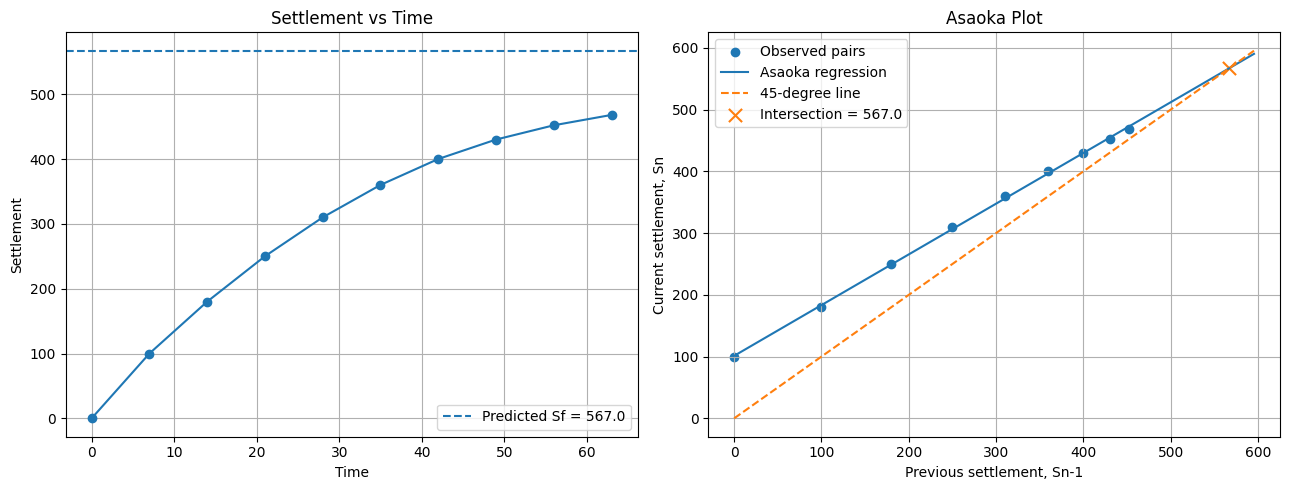

In [ ]:
def plot_asaoka(result):
    """Plot time-settlement and Asaoka regression diagrams."""
    t, s = result["time"], result["settlement"]
    x, y = result["settlement_previous"], result["settlement_current"]
    beta0, beta1 = result["beta0"], result["beta1"]
    sf = result["final_settlement"]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].plot(t, s, marker="o")
    axes[0].axhline(sf, linestyle="--", label=f"Predicted Sf = {sf:.1f}")
    axes[0].set_xlabel("Time")
    axes[0].set_ylabel("Settlement")
    axes[0].set_title("Settlement vs Time")
    axes[0].grid(True)
    axes[0].legend()

    upper = max(float(np.max(x)), float(np.max(y)), sf)*1.05
    line = np.linspace(0, upper, 100)
    axes[1].scatter(x, y, label="Observed pairs")
    axes[1].plot(line, beta0+beta1*line, label="Asaoka regression")
    axes[1].plot(line, line, linestyle="--", label="45-degree line")
    axes[1].scatter([sf], [sf], marker="x", s=90, label=f"Intersection = {sf:.1f}")
    axes[1].set_xlabel("Previous settlement, Sn-1")
    axes[1].set_ylabel("Current settlement, Sn")
    axes[1].set_title("Asaoka Plot")
    axes[1].grid(True)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_asaoka(result)

## 10. Tabel hasil

In [ ]:
asaoka_pairs = pd.DataFrame({
    "Time (days)": result["pair_time"],
    "S(n-1) (mm)": result["settlement_previous"],
    "S(n) (mm)": result["settlement_current"]
})
display(asaoka_pairs)

summary = pd.DataFrame({
    "Parameter": ["Delta t", "Beta 0", "Beta 1", "R-squared",
                  "Final settlement", "U at last observation"],
    "Value": [result["delta_t"], result["beta0"], result["beta1"],
              result["r_squared"], result["final_settlement"],
              result["degree_of_consolidation"][-1]],
    "Unit": ["days", "mm", "-", "-", "mm", "%"]
})
display(summary)

,Time (days),S(n-1) (mm),S(n) (mm)
0,7.0,0.0,100.0
1,14.0,100.0,180.0
2,21.0,180.0,250.0
3,28.0,250.0,310.0
4,35.0,310.0,360.0
5,42.0,360.0,400.0
6,49.0,400.0,430.0
7,56.0,430.0,452.0
8,63.0,452.0,468.0


,Parameter,Value,Unit
0,Delta t,7.000000,days
1,Beta 0,101.235857,mm
2,Beta 1,0.821465,-
3,R-squared,0.999407,-
4,Final settlement,567.037955,mm
5,U at last observation,82.534158,%


## 11. Verifikasi hasil yang dilaporkan — studi kasus C-2

Bagian ini mengadaptasi hitung ulang manual pada dokumen tugas, Bagian B.3, halaman 6–8. Ini melengkapi regresi Asaoka ketika data monitoring mentah tidak tersedia.

**Penting:** verifikasi hasil yang dilaporkan bukan rekonstruksi regresi Asaoka. Tanpa deret settlement pada interval waktu tetap, \(\beta_0\), \(\beta_1\), dan plot Asaoka tidak dapat dihitung ulang.

Data manual STA 0+100:
- \(S_{150}=1{,}410\) mm; \(S_{final}=1{,}550\) mm; waktu evaluasi 150 hari.
- Sand platform = 3.0 m; top backfill = 0.7 m.
- Berat isi timbunan asumsi = 18 kN/m³.
- Tekanan vakum yang dibandingkan dalam hitung manual = 80 kPa.
- Asumsi residual settlement = 1 mm/bulan.

### 11.1 Derajat konsolidasi dan settlement tersisa

\[
U=\frac{S_{150}}{S_{final}}\times100\%
=\frac{1410}{1550}\times100\%=90.97\%
\]

\[
S_{remaining}=S_{final}-S_{150}=1550-1410=140\text{ mm}
\]

\[
U_{remaining}=\frac{140}{1550}\times100\%=9.03\%
\]

Kriteria pada dokumen: \(U>90\%\). Hasil 90,97% memenuhi kriteria.

In [ ]:
def verify_reported_consolidation(settlement_at_time, final_settlement, target_u=90.0):
    """Verify reported degree of consolidation without raw Asaoka time-series data."""
    s, sf, target = map(float, [settlement_at_time, final_settlement, target_u])
    if not np.all(np.isfinite([s, sf, target])) or s < 0 or sf <= 0:
        raise ValueError("Invalid settlement or target input.")
    degree = s / sf * 100.0
    remaining = sf - s
    return {
        "degree_of_consolidation_percent": degree,
        "remaining_settlement": remaining,
        "remaining_settlement_percent": remaining / sf * 100.0,
        "target_u_percent": target,
        "meets_target": degree > target
    }

c2_consolidation = verify_reported_consolidation(1410, 1550, 90)
print(f"U calculated         : {c2_consolidation['degree_of_consolidation_percent']:.2f}%")
print(f"Remaining settlement : {c2_consolidation['remaining_settlement']:.2f} mm")
print(f"Remaining ratio      : {c2_consolidation['remaining_settlement_percent']:.2f}%")
print(f"Meets U > 90%        : {c2_consolidation['meets_target']}")

U calculated         : 90.97%
Remaining settlement : 140.00 mm
Remaining ratio      : 9.03%
Meets U > 90%        : True


### 11.2 Surcharge terhadap beban final

Hitung manual pada dokumen tugas (halaman 6–7):

\[
H=3.0+0.7=3.7\text{ m}
\]

\[
q_{final}=\gamma H=18(3.7)=66.6\text{ kPa}
\]

\[
q_{surcharge,min}=1.2q_{final}=79.92\text{ kPa}
\]

Dokumen membandingkan tekanan vakum 80 kPa dengan kebutuhan 79,92 kPa. Secara aritmetika \(80>79.92\), sehingga memenuhi tipis **jika** tekanan vakum boleh diperlakukan sebagai tekanan ekuivalen surcharge untuk kriteria ini.

**Batas interpretasi:** tekanan vakum dan surcharge timbunan tidak otomatis identik dalam semua desain. Dokumen tugas tidak menunjukkan beban surcharge aktual terpisah atau dasar konversi ekuivalensinya. Karena itu, hasil ini adalah pemeriksaan berdasarkan asumsi manual, bukan konfirmasi independen beban aktual proyek.

Sensitivitas manual: \(\gamma=17,18,19,20\) kN/m³ menghasilkan \(q_{final}=62.9,66.6,70.3,74.0\) kPa; kebutuhan \(1.2q_{final}=75.48,79.92,84.36,88.80\) kPa.

In [ ]:
def calculate_final_fill_pressure(fill_height, unit_weight):
    """Calculate fill pressure q_fill = gamma * H (kPa)."""
    h, gamma = float(fill_height), float(unit_weight)
    if not np.all(np.isfinite([h, gamma])) or h < 0 or gamma <= 0:
        raise ValueError("Invalid fill height or unit weight.")
    return h * gamma


def calculate_c2_surcharge_check(
    fill_height,
    unit_weight,
    pavement_loads,
    additional_ratio=0.30,
    required_ratio=1.20
):
    """
    Reproduce the revised manual loading calculation for C-2.

    pavement_loads: list of layer pressures in kPa.
    q_final = q_fill + sum(pavement_loads)
    q_additional = additional_ratio * q_final
    q_preloading = q_final + q_additional
    """
    q_fill = calculate_final_fill_pressure(fill_height, unit_weight)
    pavement = np.asarray(pavement_loads, dtype=float)
    ratios = np.asarray([additional_ratio, required_ratio], dtype=float)

    if pavement.ndim != 1 or len(pavement) == 0:
        raise ValueError("Provide pavement layer pressures as a non-empty 1D list.")
    if not np.all(np.isfinite(pavement)) or np.any(pavement < 0):
        raise ValueError("Pavement pressures must be finite and non-negative.")
    if not np.all(np.isfinite(ratios)) or additional_ratio < 0 or required_ratio <= 0:
        raise ValueError("Invalid surcharge ratios.")

    q_pavement = float(np.sum(pavement))
    q_final = q_fill + q_pavement
    q_additional = additional_ratio * q_final
    q_preloading = q_final + q_additional
    q_required = required_ratio * q_final

    return {
        "q_fill_kpa": q_fill,
        "pavement_loads_kpa": pavement.tolist(),
        "q_pavement_kpa": q_pavement,
        "q_final_kpa": q_final,
        "additional_ratio": float(additional_ratio),
        "q_additional_kpa": q_additional,
        "q_preloading_kpa": q_preloading,
        "required_ratio": float(required_ratio),
        "q_required_kpa": q_required,
        "actual_ratio": q_preloading / q_final,
        "meets_criterion": q_preloading > q_required
    }


# Revised C-2 manual assumptions (Tugas 2, B.3, pp. 6-7)
c2_fill_height = 3.0 + 0.7
c2_gamma_fill = 18.0
c2_pavement_loads = [2.2, 4.2, 6.0]  # asphalt, base course, subbase

c2_loading = calculate_c2_surcharge_check(
    fill_height=c2_fill_height,
    unit_weight=c2_gamma_fill,
    pavement_loads=c2_pavement_loads,
    additional_ratio=0.30,
    required_ratio=1.20
)

print(f"Fill height                    : {c2_fill_height:.2f} m")
print(f"Fill pressure                  : {c2_loading['q_fill_kpa']:.2f} kPa")
print(f"Pavement pressure              : {c2_loading['q_pavement_kpa']:.2f} kPa")
print(f"  Asphalt                      : {c2_pavement_loads[0]:.2f} kPa")
print(f"  Base course                  : {c2_pavement_loads[1]:.2f} kPa")
print(f"  Subbase                      : {c2_pavement_loads[2]:.2f} kPa")
print(f"q_final                        : {c2_loading['q_final_kpa']:.2f} kPa")
print(f"Additional surcharge (30%)     : {c2_loading['q_additional_kpa']:.2f} kPa")
print(f"q_preloading                   : {c2_loading['q_preloading_kpa']:.2f} kPa")
print(f"Required minimum (1.2 q_final) : {c2_loading['q_required_kpa']:.2f} kPa")
print(f"Actual ratio                   : {c2_loading['actual_ratio']:.3f}")
print(f"Meets criterion                : {c2_loading['meets_criterion']}")

Fill height                    : 3.70 m
Fill pressure                  : 66.60 kPa
Pavement pressure              : 12.40 kPa
  Asphalt                      : 2.20 kPa
  Base course                  : 4.20 kPa
  Subbase                      : 6.00 kPa
q_final                        : 79.00 kPa
Additional surcharge (30%)     : 23.70 kPa
q_preloading                   : 102.70 kPa
Required minimum (1.2 q_final) : 94.80 kPa
Actual ratio                   : 1.300
Meets criterion                : True


### 11.3 Laju penurunan sisa

Dokumen tugas (halaman 7) menyatakan data monitoring pascaperbaikan tidak tersedia lengkap, lalu menggunakan asumsi 1 mm/bulan:

\[
S_{year}=1\times12=12\text{ mm/tahun}<20\text{ mm/tahun}
\]

Asumsi tersebut memenuhi kriteria, tetapi **bukan hasil pengukuran lapangan C-2**.

Notebook menyediakan annualisasi asumsi mm/bulan untuk mereplikasi hitung manual/sensitivitas, dan regresi settlement terhadap waktu jika data monitoring aktual tersedia.

In [ ]:
def calculate_residual_rate_from_monthly_assumption(monthly_settlement, limit_mm_per_year=20.0):
    """Convert assumed settlement rate from mm/month to mm/year."""
    monthly, limit = float(monthly_settlement), float(limit_mm_per_year)
    if not np.isfinite(monthly) or not np.isfinite(limit) or monthly < 0 or limit <= 0:
        raise ValueError("Invalid monthly rate or annual limit.")
    annual = monthly * 12.0
    return {
        "monthly_assumption_mm": monthly,
        "annual_rate_mm_per_year": annual,
        "limit_mm_per_year": limit,
        "meets_criterion": annual < limit
    }


def calculate_residual_settlement_rate(time_days, settlement_mm, limit_mm_per_year=20.0):
    """Fit settlement against time; return absolute regression slope in mm/year."""
    t = np.asarray(time_days, dtype=float)
    s = np.asarray(settlement_mm, dtype=float)
    limit = float(limit_mm_per_year)
    if t.ndim != 1 or s.ndim != 1 or len(t) != len(s) or len(t) < 2:
        raise ValueError("Provide equal 1D arrays with at least two observations.")
    if not np.all(np.isfinite(t)) or not np.all(np.isfinite(s)) or not np.isfinite(limit):
        raise ValueError("Inputs must be finite.")
    if np.any(np.diff(t) <= 0) or limit <= 0:
        raise ValueError("Time must increase and limit must be positive.")
    slope, intercept = np.polyfit(t, s, 1)
    rate = abs(float(slope)) * 365.0
    return {
        "slope_mm_per_day": float(slope),
        "residual_rate_mm_per_year": rate,
        "limit_mm_per_year": limit,
        "meets_criterion": rate < limit,
        "intercept_mm": float(intercept)
    }

# Reproduce the manual assumption: 1 mm/month (assumed, not measured).
c2_residual_assumption = calculate_residual_rate_from_monthly_assumption(1.0, 20.0)
print(f"Assumed monthly settlement : {c2_residual_assumption['monthly_assumption_mm']:.2f} mm/month")
print(f"Annualized rate            : {c2_residual_assumption['annual_rate_mm_per_year']:.2f} mm/year")
print(f"Meets < 20 mm/year         : {c2_residual_assumption['meets_criterion']}")

Assumed monthly settlement : 1.00 mm/month
Annualized rate            : 12.00 mm/year
Meets < 20 mm/year         : True


### 11.4 Sensitivitas asumsi residual settlement

Skenario berikut mereplikasi tabel sensitivitas pada dokumen tugas. Nilai adalah asumsi, bukan monitoring aktual.

In [ ]:
monthly_scenarios = [0.5, 1.0, 1.5, 1.67, 2.0]
sensitivity = pd.DataFrame([
    {
        "Assumed settlement (mm/month)": value,
        "Annualized rate (mm/year)": calculate_residual_rate_from_monthly_assumption(value)["annual_rate_mm_per_year"],
        "Meets < 20 mm/year": calculate_residual_rate_from_monthly_assumption(value)["meets_criterion"]
    }
    for value in monthly_scenarios
])
display(sensitivity)

,Assumed settlement (mm/month),Annualized rate (mm/year),Meets < 20 mm/year
0,0.50,6.00,True
1,1.00,12.00,True
2,1.50,18.00,True
3,1.67,20.04,False
4,2.00,24.00,False


### 11.5 Catatan batas penurunan 100 mm

Tabel kriteria pada dokumen tugas (halaman 4) juga mencantumkan “penurunan total < 100 mm”. Pada hitung ulang halaman 7, sisa settlement \(S_{final}-S_{150}=140\) mm dibandingkan dengan batas 100 mm dan dinyatakan belum memenuhi secara konservatif.

Perlu hati-hati: sisa settlement menuju akhir konsolidasi (140 mm) tidak otomatis identik dengan definisi “penurunan total” pascakonstruksi. Notebook melaporkan sisa 140 mm, tetapi tidak menetapkan keputusan final atas kriteria 100 mm tanpa definisi periode dan datum yang lebih jelas.

## 12. Unit test

Pengujian meliputi interval tetap, regresi dengan parameter diketahui, settlement akhir, derajat konsolidasi, dan validasi input.

In [ ]:
# Test 1: equally spaced observations
prepared_test = prepare_asaoka_data([0, 7, 14, 21], [0, 10, 18, 24])
assert prepared_test["delta_t"] == 7.0
assert np.allclose(prepared_test["settlement_previous"], [0, 10, 18])

# Test 2: exact relationship Sn = 10 + 0.8 * Sn-1
fit_test = calculate_asaoka([0, 10, 20, 30], [10, 18, 26, 34])
assert np.isclose(fit_test["beta0"], 10.0)
assert np.isclose(fit_test["beta1"], 0.8)

# Test 3: final settlement
assert np.isclose(fit_test["final_settlement"], 50.0)

# Test 4: degree of consolidation with non-zero datum
u_test = calculate_degree_of_consolidation([100, 120, 140], 200, 100)
assert np.allclose(u_test, [0, 20, 40])

# Test 5: reject irregular intervals
try:
    prepare_asaoka_data([0, 7, 15, 21], [0, 10, 18, 24])
    raise AssertionError("Irregular intervals should raise ValueError.")
except ValueError:
    pass

# Test 6: reject beta1 >= 1
try:
    calculate_asaoka([0, 10, 20], [1, 11, 21])
    raise AssertionError("beta1 >= 1 should raise ValueError.")
except ValueError:
    pass

# Test 7: reported consolidation verification
c = verify_reported_consolidation(1410, 1550, 90)
assert np.isclose(c["degree_of_consolidation_percent"], 90.9677419355)
assert c["meets_target"] is True

# Test 8: revised C-2 fill + pavement + surcharge calculation
loading_test = calculate_c2_surcharge_check(
    fill_height=3.7,
    unit_weight=18.0,
    pavement_loads=[2.2, 4.2, 6.0],
    additional_ratio=0.30,
    required_ratio=1.20
)
assert np.isclose(loading_test["q_fill_kpa"], 66.6)
assert np.isclose(loading_test["q_pavement_kpa"], 12.4)
assert np.isclose(loading_test["q_final_kpa"], 79.0)
assert np.isclose(loading_test["q_additional_kpa"], 23.7)
assert np.isclose(loading_test["q_preloading_kpa"], 102.7)
assert np.isclose(loading_test["q_required_kpa"], 94.8)
assert np.isclose(loading_test["actual_ratio"], 1.30)
assert loading_test["meets_criterion"] is True

# Test 9: assumed monthly residual rate
rr = calculate_residual_rate_from_monthly_assumption(1.0, 20)
assert np.isclose(rr["annual_rate_mm_per_year"], 12.0)
assert rr["meets_criterion"] is True

# Test 10: residual rate from illustrative monitoring observations
rr_data = calculate_residual_settlement_rate([0, 30, 60], [100, 101, 102], 20)
assert np.isclose(rr_data["residual_rate_mm_per_year"], 12.1666666667)

print("All M4 unit tests passed (10 tests).")

All M4 unit tests passed (10 tests).


## 13. Interpretasi, batasan, dan studi kasus C-2

- \(S_f\) adalah estimasi ekstrapolasi observasional, bukan pembacaan langsung.
- \(R^2\) membantu memeriksa linearitas pasangan data, tetapi nilai tinggi tidak otomatis menjamin prediksi benar.
- Pilih rentang data dengan mempertimbangkan tahapan konstruksi dan perubahan beban.
- Jika interval monitoring tidak tetap, pilih data pada interval konstan yang dapat dipertanggungjawabkan. Notebook tidak melakukan interpolasi otomatis.
- Secondary settlement dapat memengaruhi hasil; interpretasi harus mempertimbangkan konteks proyek.
- Modul ini tidak menghitung stabilitas timbunan, tekanan air pori, atau izin pelepasan surcharge secara otomatis.

**Kaitan dengan C-2:** presentasi menampilkan monitoring settlement terhadap waktu (slide 108), ringkasan hasil Zone 1 (slide 106), serta metode Asaoka dan catatan pengaruh \(\Delta t\), secondary settlement, dan data awal (slide 111).

Slide 106 mencantumkan contoh STA 0+100: \(S_{150}=1{,}410\) mm, \(S_f=1{,}550\) mm, dan \(U=90.97\\%\). Angka tersebut dapat memeriksa rasio settlement, tetapi belum cukup untuk mereproduksi regresi Asaoka tanpa deret pembacaan settlement berinterval tetap.

**Validasi numerik penuh terhadap C-2 belum dilakukan** karena data mentah berurutan belum tersedia sebagai tabel.

### Referensi
1. Asaoka, A. (1978). *Observational Procedure of Settlement Prediction*. Soils and Foundations, 18(4), 87–101. DOI: https://doi.org/10.3208/sandf1972.18.4_87
2. Materi kuliah MPT Minggu 3, Bagian 3.6, halaman slide 53 — *The Asaoka Method: Reading the Final Settlement Off the Data*.
3. Presentasi *Pengalaman Perbaikan Tanah*, slide 106, 108, dan 111.
4. Arafianto et al., *Jurnal Teknik Sipil ITB*, bagian 3.2.1 — metode Asaoka.
5. Yang, W., Ouyang, J., Wang, Z., Xie, Y., Meng, J., & Zhang, C. (2026). *Post-Construction Settlement Prediction of Deep Lacustrine-Fluvial Soft Ground Improved by Vacuum Wellpoint Dewatering and Dynamic Compaction: An Engineering Case Study*. Technologies, 14(9), 590. https://doi.org/10.3390/technologies14090590
6. Dokumen Tugas 2, *Naufal Javaroso — Tugas 2*, Bagian B.3–B.4, halaman 6–8.

### Update note — revised C-2 surcharge calculation

The surcharge calculation above follows the revised manual report (B.3, pp. 6–7). It replaces the earlier simplified comparison of 80 kPa against \(1.2q_{fill}\). The revised calculation includes pavement pressure (12.4 kPa), then adds 30% of \(q_{final}\) to obtain \(q_{preloading}\). The acceptance check compares \(q_{preloading}\) with \(1.2q_{final}\).

This is an arithmetic reproduction of the assumptions in the report. The report does not establish that the assumed pavement loads, fill unit weight, or 30% additional surcharge are verified as-built project measurements.

## Validation case — Yang et al. (2026): full Asaoka workflow

**Primary source:** Yang, W., Ouyang, J., Wang, Z., Xie, Y., Meng, J., & Zhang, C. (2026). “Post-Construction Settlement Prediction of Deep Lacustrine-Fluvial Soft Ground Improved by Vacuum Wellpoint Dewatering and Dynamic Compaction: An Engineering Case Study.” *Technologies*, 14(9), 590. https://doi.org/10.3390/technologies14090590.

**Traceability in the paper**
- Section 2.4: field monitoring dataset and measurement accuracy.
- Section 4.1, Equation (1)–(4): Asaoka regression and asymptotic settlement.
- Table 4: archived field settlement observations (12 observations, 30-day interval).
- Table 5: paired settlement observations used for the illustrative Asaoka fit.
- Section 4.2, Table 9: out-of-sample RMSE/MAE for calibration windows ending at Days 180, 240, and 300.

The article reports that the archived series contains 12 observations from Day 30 to Day 360 at a constant 30-day interval. It states Class IV precision-levelling accuracy of ±1 mm. The displayed 0.01 mm precision is retained to reproduce the archived calculation dataset, not interpreted as field measurement accuracy.

### Published field data

| Time (day) | Settlement (mm) |
|---:|---:|
| 30 | 92.84 |
| 60 | 101.96 |
| 90 | 105.21 |
| 120 | 106.97 |
| 150 | 107.86 |
| 180 | 108.33 |
| 210 | 108.55 |
| 240 | 108.67 |
| 270 | 108.74 |
| 300 | 108.79 |
| 330 | 108.82 |
| 360 | 108.84 |

### Asaoka pair selection

The paper states that pairs from Day 90 onward are used for the regression to reduce the influence of the first two early-stage pairs. In the input series, this means using the observation at Day 60 as the first \(S_{n-1}\), and Day 90 as the first \(S_n\). Therefore, the validation calls `analyze_asaoka(..., start_time=60)` so that the generated pair times are Day 90–360.

\[
S_n=\beta_0+\beta_1S_{n-1}
\qquad
S_f=\frac{\beta_0}{1-\beta_1}
\]

The published full-series fit is:
\[
S_n=51.715+0.5248S_{n-1}
\]
\[
S_f\approx108.837\text{ mm}
\]

### Independent predictive check

The paper also refits the Asaoka relationship using calibration windows ending at Days 180, 240, and 300, then recursively predicts only the subsequent withheld observations. The resulting RMSE/MAE are compared with Section 4.2, Table 9.

**Interpretation limit:** Day 360 (108.84 mm) is the last available observation, not a proven ultimate settlement. The paper explicitly notes ±1 mm levelling accuracy; sub-millimetre numerical differences are not evidence of field measurement precision.

,Pair time (day),S_(n-1) (mm),S_n (mm)
0,90.0,101.96,105.21
1,120.0,105.21,106.97
2,150.0,106.97,107.86
3,180.0,107.86,108.33
4,210.0,108.33,108.55
5,240.0,108.55,108.67
6,270.0,108.67,108.74
7,300.0,108.74,108.79
8,330.0,108.79,108.82
9,360.0,108.82,108.84


Full-series Asaoka validation — Yang et al. (2026)
Constant interval       : 30.0 days
Number of Asaoka pairs  : 10
beta0                   : 51.715062 mm (paper: 51.715)
beta1                   : 0.524843 (paper: 0.5248)
R-squared               : 0.999779 (diagnostic)
Ultimate settlement Sf  : 108.8379 mm (paper: ~108.837 mm)


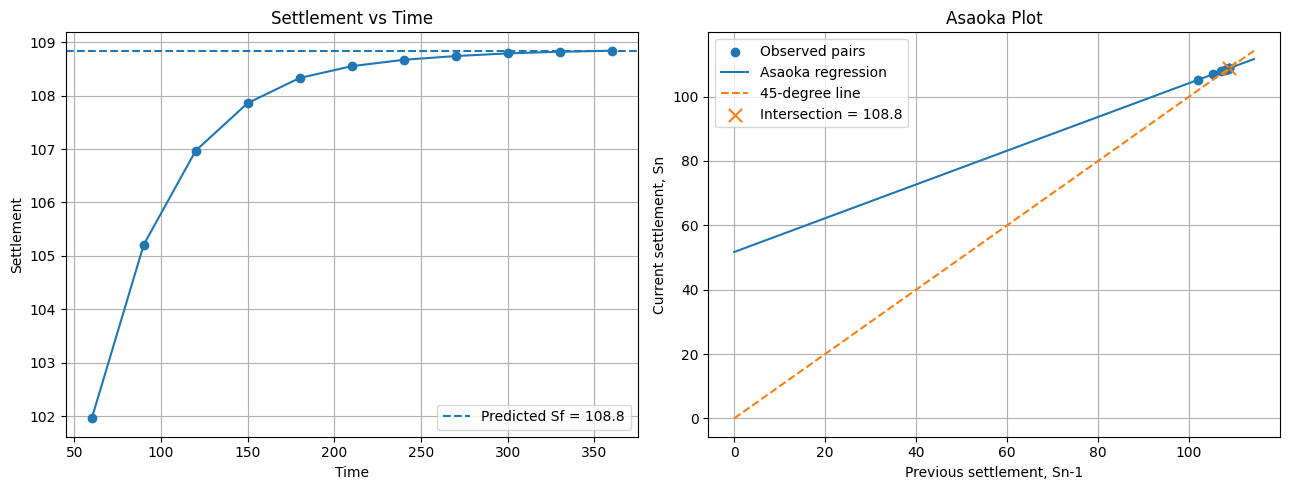

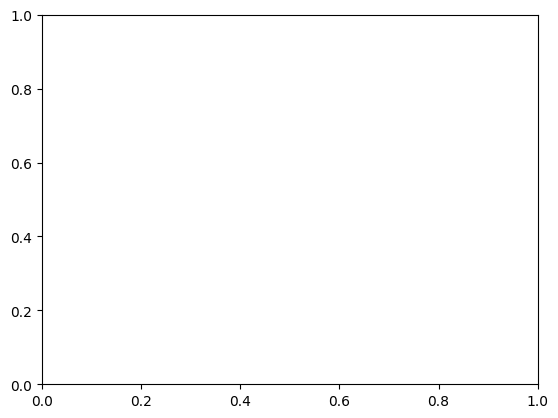

In [ ]:
# Yang et al. (2026), Table 4 and Section 4.1, Eq. (1)-(4)
yang_time_days = [30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360]
yang_settlement_mm = [
    92.84, 101.96, 105.21, 106.97, 107.86, 108.33,
    108.55, 108.67, 108.74, 108.79, 108.82, 108.84
]

# Full Asaoka workflow. start_time=60 retains the Day-60 reading as S_(n-1),
# making the first regression pair (Day 60, Day 90), as described in Section 4.1.
yang_result = analyze_asaoka(
    yang_time_days,
    yang_settlement_mm,
    start_time=60
)

# Published rounded full-series values: beta0=51.715, beta1=0.5248, Sf=108.837 mm.
assert np.isclose(yang_result["delta_t"], 30.0)
assert np.isclose(yang_result["beta0"], 51.715, atol=0.002)
assert np.isclose(yang_result["beta1"], 0.5248, atol=0.0001)
assert np.isclose(yang_result["final_settlement"], 108.837, atol=0.003)

yang_pairs = pd.DataFrame({
    "Pair time (day)": yang_result["pair_time"],
    "S_(n-1) (mm)": yang_result["settlement_previous"],
    "S_n (mm)": yang_result["settlement_current"]
})
display(yang_pairs)

print("Full-series Asaoka validation — Yang et al. (2026)")
print(f"Constant interval       : {yang_result['delta_t']:.1f} days")
print(f"Number of Asaoka pairs  : {len(yang_result['settlement_previous'])}")
print(f"beta0                   : {yang_result['beta0']:.6f} mm (paper: 51.715)")
print(f"beta1                   : {yang_result['beta1']:.6f} (paper: 0.5248)")
print(f"R-squared               : {yang_result['r_squared']:.6f} (diagnostic)")
print(f"Ultimate settlement Sf  : {yang_result['final_settlement']:.4f} mm (paper: ~108.837 mm)")

# Plot both time-settlement and Asaoka regression using the actual published series.
plot_asaoka(yang_result)
plt.show()

### Out-of-sample Asaoka validation — Yang et al. (2026), Section 4.2, Table 9

For each calibration end date, the model is fitted only to pairs whose current observation time is at or before the cutoff. Future observations are withheld. The prediction is then generated recursively at the same 30-day interval.

This reproduces the paper's validation protocol for the Asaoka method. It is separate from the full-series descriptive fit above.

In [ ]:
# Recreate the paper's three calibration windows and withheld predictions.
pair_time = np.asarray(yang_result["pair_time"], dtype=float)
pair_x = np.asarray(yang_result["settlement_previous"], dtype=float)
pair_y = np.asarray(yang_result["settlement_current"], dtype=float)
obs_time = np.asarray(yang_time_days, dtype=float)
obs_settlement = np.asarray(yang_settlement_mm, dtype=float)

yang_oos_rows = []
yang_oos_predictions = {}

for cutoff in [180, 240, 300]:
    train_mask = pair_time <= cutoff
    fitted = calculate_asaoka(pair_x[train_mask], pair_y[train_mask])

    future_mask = obs_time > cutoff
    future_times = obs_time[future_mask]
    actual = obs_settlement[future_mask]

    prediction = []
    next_settlement = float(obs_settlement[obs_time == cutoff][0])
    for _ in future_times:
        next_settlement = (
            fitted["beta0"] + fitted["beta1"] * next_settlement
        )
        prediction.append(next_settlement)

    prediction = np.asarray(prediction, dtype=float)
    rmse = float(np.sqrt(np.mean((actual - prediction) ** 2)))
    mae = float(np.mean(np.abs(actual - prediction)))
    day360_prediction = float(prediction[-1])

    yang_oos_predictions[cutoff] = {
        "time": future_times,
        "actual": actual,
        "predicted": prediction,
        "beta0": fitted["beta0"],
        "beta1": fitted["beta1"]
    }
    yang_oos_rows.append({
        "Calibration end (day)": cutoff,
        "beta0 (mm)": fitted["beta0"],
        "beta1": fitted["beta1"],
        "RMSE (mm)": rmse,
        "MAE (mm)": mae,
        "Predicted S at Day 360 (mm)": day360_prediction
    })

yang_oos_table = pd.DataFrame(yang_oos_rows)
display(yang_oos_table)

# Published Table 9 rounded benchmarks: RMSE/MAE = 0.04/0.04,
# 0.01/0.01, and 0.02/0.02 mm for the three Asaoka calibration windows.
published_rmse = np.array([0.04, 0.01, 0.02])
published_mae = np.array([0.04, 0.01, 0.02])
calculated_rmse = yang_oos_table["RMSE (mm)"].to_numpy()
calculated_mae = yang_oos_table["MAE (mm)"].to_numpy()

assert np.all(np.abs(calculated_rmse - published_rmse) < 0.006)
assert np.all(np.abs(calculated_mae - published_mae) < 0.006)

# Paper's Day-360 Asaoka predictions, rounded to 2 decimal places:
# 108.86, 108.82, and 108.82 mm.
published_day360 = np.array([108.86, 108.82, 108.82])
calculated_day360 = yang_oos_table["Predicted S at Day 360 (mm)"].to_numpy()
assert np.all(np.abs(calculated_day360 - published_day360) < 0.006)

print("Out-of-sample checks against Yang et al. (2026), Table 9")
for _, row in yang_oos_table.iterrows():
    print(
        f"Cutoff Day {int(row['Calibration end (day)'])}: "
        f"RMSE={row['RMSE (mm)']:.4f} mm, "
        f"MAE={row['MAE (mm)']:.4f} mm, "
        f"S360={row['Predicted S at Day 360 (mm)']:.4f} mm"
    )
print("All full-series and out-of-sample Asaoka validation checks passed.")

,Calibration end (day),beta0 (mm),beta1,RMSE (mm),MAE (mm),Predicted S at Day 360 (mm)
0,180,51.359948,0.528271,0.042654,0.041207,108.864012
1,240,51.812778,0.523906,0.013926,0.011807,108.817001
2,300,51.802896,0.524001,0.016833,0.016064,108.818905


Out-of-sample checks against Yang et al. (2026), Table 9
Cutoff Day 180: RMSE=0.0427 mm, MAE=0.0412 mm, S360=108.8640 mm
Cutoff Day 240: RMSE=0.0139 mm, MAE=0.0118 mm, S360=108.8170 mm
Cutoff Day 300: RMSE=0.0168 mm, MAE=0.0161 mm, S360=108.8189 mm
All full-series and out-of-sample Asaoka validation checks passed.
